# Parallel Island-Model Memetic Algorithm for the TSP (MPI + OpenMP)
**Tanush Rajaram Lokhande · Roll No 241080035 · Parallel Computing Mini Project**

Run this notebook top to bottom on Google Colab (**Runtime → Run all**). It will:
1. install OpenMPI and compile three versions of the solver (serial, OpenMP-only, hybrid MPI+OpenMP),
2. run a quick demo,
3. run the experiments: scaling (speedup/efficiency), migration study, and plain GA vs memetic GA,
4. plot the results and the best tour.

**Method:** island model over MPI (ring migration, asynchronous), OpenMP threads inside each island,
OX crossover + 2-opt/Or-opt local search with neighbour lists (memetic), duplicate removal and stagnation kicks.

> Colab's free tier gives only about 2 CPU cores, so speedups above 2x are not expected there.
> For larger core counts, run the same code on a cluster or a bigger machine.

## 1. Setup: install MPI and check the machine

In [ ]:
!apt-get -qq update > /dev/null
!apt-get -qq install -y libopenmpi-dev openmpi-bin > /dev/null
!mpirun --version | head -1
!g++ --version | head -1
import os
print("CPU cores available:", os.cpu_count())

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
mpirun (Open MPI) 4.1.6
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
CPU cores available: 2


## 2. Source code
The solver is a single C++ file; the preprocessor flags choose the serial, OpenMP or hybrid build.

In [ ]:
%%writefile tsp_ga.cpp
// =============================================================================
//  Hybrid Island-Model Memetic Algorithm for the TSP  (MPI + OpenMP)
//  Author : Tanush Rajaram Lokhande (241080035)
//
//  ONE source file, THREE executables (see Makefile):
//     serial  : g++ -O3                              (no MPI, no OpenMP)
//     omp     : g++ -O3 -fopenmp                     (shared-memory only)
//     hybrid  : mpicxx -O3 -fopenmp -DUSE_MPI        (islands + threads)
//
//  Improvements over a textbook GA (see README for the research basis):
//   1. Memetic search: offspring are refined by 2-opt + Or-opt local search
//      with K-nearest-neighbour candidate lists and a work queue
//      ("don't-look bits" idea, Bentley 1992).
//   2. Population diversity management: edge-set hashing removes duplicate
//      tours; a stagnation detector re-injects kicked (double-bridge) tours.
//   3. Heterogeneous islands: mutation rate differs per island (explore/exploit).
//   4. Asynchronous ring migration with non-blocking MPI (Isend/Irecv/Test):
//      islands never wait for each other.
//   5. MPI-3 shared-memory window: ONE copy of the distance matrix per node,
//      shared by all ranks on that node.
//   6. Thread-count-independent determinism: every offspring has its own RNG
//      stream derived from (seed, generation, index).
// =============================================================================
#include <algorithm>
#include <chrono>
#include <climits>
#include <cmath>
#include <cstdint>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <fstream>
#include <iostream>
#include <sstream>
#include <string>
#include <unordered_set>
#include <vector>
#ifdef _OPENMP
#include <omp.h>
#endif
#ifdef USE_MPI
#include <mpi.h>
#endif
using namespace std;

// ------------------------------------------------------------------ helpers --
static inline int thr_id() {
#ifdef _OPENMP
    return omp_get_thread_num();
#else
    return 0;
#endif
}
static inline int thr_max() {
#ifdef _OPENMP
    return omp_get_max_threads();
#else
    return 1;
#endif
}
static inline uint64_t mix64(uint64_t z) {
    z += 0x9E3779B97F4A7C15ULL;
    z = (z ^ (z >> 30)) * 0xBF58476D1CE4E5B9ULL;
    z = (z ^ (z >> 27)) * 0x94D049BB133111EBULL;
    return z ^ (z >> 31);
}
struct Rng {  // splitmix64 : tiny, fast, good enough, trivially seedable
    uint64_t s;
    explicit Rng(uint64_t seed = 1) : s(seed) {}
    uint64_t next() { s += 0x9E3779B97F4A7C15ULL; return mix64(s); }
    int below(int n) { return (int)(next() % (uint64_t)n); }
    double real() { return (next() >> 11) * (1.0 / 9007199254740992.0); }
};
static double now_sec() {
    using namespace chrono;
    return duration<double>(steady_clock::now().time_since_epoch()).count();
}

// ----------------------------------------------------------------- instance --
struct Instance {
    string name = "random";
    int n = 0;
    vector<double> x, y;
    int etype = 0;  // 0 EUC_2D, 1 CEIL_2D, 2 ATT
    int K = 0;
    vector<int> nbr;            // n*K nearest neighbours
    const int* mat = nullptr;   // optional full distance matrix
    vector<int> matStore;       // used by non-MPI builds
} G;

static inline int calcDist(int i, int j) {
    double dx = G.x[i] - G.x[j], dy = G.y[i] - G.y[j];
    if (G.etype == 2) {
        double r = sqrt((dx * dx + dy * dy) / 10.0);
        int t = (int)(r + 0.5);
        return t < r ? t + 1 : t;
    }
    double e = sqrt(dx * dx + dy * dy);
    return G.etype == 1 ? (int)ceil(e) : (int)(e + 0.5);
}
static inline int D(int i, int j) { return G.mat ? G.mat[(size_t)i * G.n + j] : calcDist(i, j); }

static bool loadTSPLIB(const string& path) {
    ifstream f(path);
    if (!f) return false;
    string line;
    bool coords = false;
    int dim = 0;
    size_t sl = path.find_last_of("/\\");
    G.name = path.substr(sl == string::npos ? 0 : sl + 1);
    while (getline(f, line)) {
        if (coords) {
            if (line.find("EOF") != string::npos) break;
            istringstream ss(line);
            int id; double a, b;
            if (ss >> id >> a >> b) { G.x.push_back(a); G.y.push_back(b); }
            continue;
        }
        size_t c = line.find(':');
        string val = c == string::npos ? "" : line.substr(c + 1);
        val.erase(0, val.find_first_not_of(" \t\r\n"));
        if (line.find("DIMENSION") != string::npos) dim = atoi(val.c_str());
        else if (line.find("EDGE_WEIGHT_TYPE") != string::npos) {
            if (val.rfind("CEIL_2D", 0) == 0) G.etype = 1;
            else if (val.rfind("ATT", 0) == 0) G.etype = 2;
            else if (val.rfind("EUC_2D", 0) == 0) G.etype = 0;
            else { fprintf(stderr, "Unsupported EDGE_WEIGHT_TYPE: %s\n", val.c_str()); return false; }
        } else if (line.find("NODE_COORD_SECTION") != string::npos) coords = true;
    }
    G.n = (int)G.x.size();
    if (dim && dim != G.n) fprintf(stderr, "warning: DIMENSION=%d but read %d coords\n", dim, G.n);
    return G.n >= 8;
}
static void makeRandom(int n, uint64_t seed) {
    Rng r(seed ^ 0xABCDEF);
    G.n = n; G.name = "random" + to_string(n);
    for (int i = 0; i < n; i++) { G.x.push_back(r.real() * 1000); G.y.push_back(r.real() * 1000); }
}

#ifdef USE_MPI
static MPI_Win g_win = MPI_WIN_NULL;
static const int* buildSharedMatrix() {  // MPI-3 shared memory: one matrix per node
    int n = G.n;
    MPI_Comm node;
    MPI_Comm_split_type(MPI_COMM_WORLD, MPI_COMM_TYPE_SHARED, 0, MPI_INFO_NULL, &node);
    int nr, ns;
    MPI_Comm_rank(node, &nr); MPI_Comm_size(node, &ns);
    MPI_Aint bytes = (nr == 0) ? (MPI_Aint)n * n * (MPI_Aint)sizeof(int) : 0;
    int* base = nullptr;
    MPI_Win_allocate_shared(bytes, sizeof(int), MPI_INFO_NULL, node, &base, &g_win);
    if (nr != 0) { MPI_Aint sz; int du; MPI_Win_shared_query(g_win, 0, &sz, &du, &base); }
    MPI_Win_lock_all(MPI_MODE_NOCHECK, g_win);
#pragma omp parallel for schedule(static)
    for (int i = 0; i < n; i++)
        if (i % ns == nr)
            for (int j = 0; j < n; j++) base[(size_t)i * n + j] = calcDist(i, j);
    MPI_Win_sync(g_win);
    MPI_Barrier(node);
    MPI_Win_sync(g_win);
    MPI_Comm_free(&node);
    return base;
}
#endif

static const int MAT_LIMIT = 4500;  // n above this -> compute distances on the fly
static void buildDistances(int Kwanted) {
    const int n = G.n;
    if (n <= MAT_LIMIT) {
#ifdef USE_MPI
        G.mat = buildSharedMatrix();
#else
        G.matStore.resize((size_t)n * n);
#pragma omp parallel for schedule(static)
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++) G.matStore[(size_t)i * n + j] = calcDist(i, j);
        G.mat = G.matStore.data();
#endif
    }
    G.K = min(Kwanted, n - 1);
    G.nbr.assign((size_t)n * G.K, 0);
#pragma omp parallel
    {
        vector<pair<int, int>> tmp;
        tmp.reserve(n);
#pragma omp for schedule(static)
        for (int i = 0; i < n; i++) {
            tmp.clear();
            for (int j = 0; j < n; j++) if (j != i) tmp.push_back({D(i, j), j});
            partial_sort(tmp.begin(), tmp.begin() + G.K, tmp.end());
            for (int k = 0; k < G.K; k++) G.nbr[(size_t)i * G.K + k] = tmp[k].second;
        }
    }
}

// ------------------------------------------------------------------- tours --
struct Ind { vector<int> t; long long len = 0; uint64_t h = 0; };

static long long tourLen(const int* t) {
    long long s = 0;
    for (int i = 0, n = G.n; i < n; i++) s += D(t[i], t[i + 1 == n ? 0 : i + 1]);
    return s;
}
static uint64_t tourHash(const int* t) {  // orientation/rotation independent
    uint64_t h = 0;
    for (int i = 0, n = G.n; i < n; i++) {
        uint64_t a = t[i], b = t[i + 1 == n ? 0 : i + 1];
        if (a > b) swap(a, b);
        h += mix64((a << 32) | b);
    }
    return h;
}
static void finalizeInd(Ind& I) { I.len = tourLen(I.t.data()); I.h = tourHash(I.t.data()); }
static bool byLen(const Ind& a, const Ind& b) { return a.len < b.len; }

struct Work {  // per-thread scratch space
    vector<int> pos, stk, tmp;
    vector<char> inq, used;
    void init(int n) {
        pos.assign(n, 0); tmp.assign(n, 0); inq.assign(n, 0); used.assign(n, 0);
        stk.clear(); stk.reserve(2 * n);
    }
};
static inline void pushQ(Work& w, int c) { if (!w.inq[c]) { w.inq[c] = 1; w.stk.push_back(c); } }

// ---------------------------------------------- local search: 2-opt + Or-opt --
static void localSearch(int* t, Work& w) {
    const int n = G.n, K = G.K;
    if (n < 8) return;
    for (int i = 0; i < n; i++) w.pos[t[i]] = i;
    w.stk.clear();
    for (int i = n - 1; i >= 0; i--) { w.inq[t[i]] = 1; w.stk.push_back(t[i]); }
    auto nx = [&](int c) { int p = w.pos[c] + 1; return t[p == n ? 0 : p]; };
    auto pv = [&](int c) { int p = w.pos[c] - 1; return t[p < 0 ? n - 1 : p]; };
    auto rev = [&](int i, int j) {  // reverse cyclic path pos i..j, choosing the shorter side
        int len = j - i; if (len < 0) len += n; len += 1;
        if (len * 2 > n) {
            int ni = j + 1 == n ? 0 : j + 1, nj = i == 0 ? n - 1 : i - 1;
            i = ni; j = nj; len = n - len;
        }
        for (int k = len / 2; k > 0; k--) {
            int a = t[i], b = t[j];
            t[i] = b; w.pos[b] = i; t[j] = a; w.pos[a] = j;
            if (++i == n) i = 0;
            if (--j < 0) j = n - 1;
        }
    };
    while (!w.stk.empty()) {
        int a = w.stk.back(); w.stk.pop_back(); w.inq[a] = 0;
        bool improved = false;
        // ---- 2-opt with neighbour lists (both tour directions)
        for (int dir = 0; dir < 2 && !improved; dir++) {
            int b = dir == 0 ? nx(a) : pv(a);
            int dab = D(a, b);
            for (int k = 0; k < K; k++) {
                int c = G.nbr[(size_t)a * K + k];
                int dac = D(a, c);
                if (dac >= dab) break;
                int d = dir == 0 ? nx(c) : pv(c);
                if (c == b || d == a) continue;
                int delta = dab + D(c, d) - dac - D(b, d);
                if (delta > 0) {
                    if (dir == 0) rev(w.pos[b], w.pos[c]); else rev(w.pos[a], w.pos[d]);
                    pushQ(w, a); pushQ(w, b); pushQ(w, c); pushQ(w, d);
                    improved = true; break;
                }
            }
        }
        if (improved) continue;
        // ---- Or-opt: move a segment of 1..3 cities next to a near neighbour of a
        for (int L = 1; L <= 3 && !improved; L++) {
            for (int side = 0; side < 2 && !improved; side++) {
                if (L == 1 && side == 1) continue;
                int s1 = a, sL = a;
                if (side == 0) for (int i = 1; i < L; i++) sL = nx(sL);
                else for (int i = 1; i < L; i++) s1 = pv(s1);
                int p = pv(s1), nn = nx(sL);
                int base = D(p, s1) + D(sL, nn) - D(p, nn);
                if (base <= 0) continue;
                int sp = w.pos[s1];
                auto inSeg = [&](int x) { int o = w.pos[x] - sp; if (o < 0) o += n; return o < L; };
                for (int k = 0; k < K && !improved; k++) {
                    int c = G.nbr[(size_t)a * K + k];
                    if (D(a, c) >= base) break;
                    if (inSeg(c)) continue;
                    for (int e = 0; e < 2 && !improved; e++) {
                        int ca = e == 0 ? c : pv(c), eb = e == 0 ? nx(c) : c;
                        if (inSeg(ca) || inSeg(eb)) continue;
                        bool rv = ((side == 0) == (e == 1));
                        int added = rv ? D(ca, sL) + D(s1, eb) : D(ca, s1) + D(sL, eb);
                        int delta = base + D(ca, eb) - added;
                        if (delta <= 0) continue;
                        int idx = 0, cur = nn;
                        for (;;) {
                            w.tmp[idx++] = cur;
                            if (cur == ca) {
                                if (!rv) { int x = s1; for (int i = 0; i < L; i++) { w.tmp[idx++] = x; x = nx(x); } }
                                else     { int x = sL; for (int i = 0; i < L; i++) { w.tmp[idx++] = x; x = pv(x); } }
                            }
                            if (cur == p) break;
                            cur = nx(cur);
                        }
                        for (int i = 0; i < n; i++) { t[i] = w.tmp[i]; w.pos[t[i]] = i; }
                        pushQ(w, p); pushQ(w, nn); pushQ(w, s1); pushQ(w, sL); pushQ(w, ca); pushQ(w, eb);
                        improved = true;
                    }
                }
            }
        }
    }
}

// ------------------------------------------------------ construction/operators --
static void nearestNeighbour(int* t, int start, Work& w) {
    const int n = G.n, K = G.K;
    fill(w.used.begin(), w.used.end(), 0);
    int cur = start; t[0] = start; w.used[start] = 1;
    for (int i = 1; i < n; i++) {
        int best = -1;
        for (int k = 0; k < K; k++) { int c = G.nbr[(size_t)cur * K + k]; if (!w.used[c]) { best = c; break; } }
        if (best < 0) {
            int bd = INT_MAX;
            for (int c = 0; c < n; c++) if (!w.used[c]) { int d = D(cur, c); if (d < bd) { bd = d; best = c; } }
        }
        t[i] = best; w.used[best] = 1; cur = best;
    }
}
static void randomTour(int* t, Rng& r) {
    int n = G.n;
    for (int i = 0; i < n; i++) t[i] = i;
    for (int i = n - 1; i > 0; i--) swap(t[i], t[r.below(i + 1)]);
}
static void doubleBridge(int* t, Rng& r, Work& w) {  // local (windowed) double-bridge kick
    int n = G.n;
    if (n < 8) return;
    int W = min(n - 1, 100), s = r.below(n - W), c[3];
    do { for (int i = 0; i < 3; i++) c[i] = s + 1 + r.below(W); sort(c, c + 3); } while (c[0] == c[1] || c[1] == c[2]);
    int idx = c[0];
    for (int i = c[1]; i < c[2]; i++) w.tmp[idx++] = t[i];
    for (int i = c[0]; i < c[1]; i++) w.tmp[idx++] = t[i];
    for (int i = c[0]; i < c[2]; i++) t[i] = w.tmp[i];
}
static void inversion(int* t, Rng& r) {
    int n = G.n, i = r.below(n), j = r.below(n);
    if (i > j) swap(i, j);
    reverse(t + i, t + j + 1);
}
static void orderCrossover(const int* p1, const int* p2, int* ch, Rng& r, Work& w) {
    int n = G.n, a = r.below(n), b = r.below(n);
    if (a > b) swap(a, b);
    fill(w.used.begin(), w.used.end(), 0);
    for (int i = a; i <= b; i++) { ch[i] = p1[i]; w.used[p1[i]] = 1; }
    int idx = (b + 1) % n, src = idx;
    for (int k = 0; k < n; k++) {
        int c = p2[src]; if (++src == n) src = 0;
        if (!w.used[c]) { ch[idx] = c; if (++idx == n) idx = 0; }
    }
}

// --------------------------------------------------------------------- params --
struct Params {
    string tsp, csv, trace, out;
    int randomN = 0, pop = 48, gens = 200, migInt = 10, migCount = 2, threads = 0;
    int ls = 1, strong = 0, stag = 40, K = 10, tour = 3;
    uint64_t seed = 1;
    double pm = -1;      // <0 : auto (heterogeneous islands)
    long long opt = 0;   // best known value (for gap)
};
static void usage() {
    puts("Usage: tsp_ga (--tsp file.tsp | --random N) [options]\n"
         "  --pop P          population per island (default 48)\n"
         "  --strong         treat --pop as TOTAL population and split across islands\n"
         "  --gens G         generations (default 200)\n"
         "  --mig-int I      migrate every I generations (default 10; 0 = isolated islands)\n"
         "  --mig-count M    tours sent per migration (default 2)\n"
         "  --threads T      OpenMP threads per process\n"
         "  --ls 0|1         local search on offspring (memetic) (default 1)\n"
         "  --pm x           mutation probability (default: auto per island)\n"
         "  --stag S         inject kicked tours after S stagnant gens (0=off)\n"
         "  --seed s  --opt best_known  --csv file  --trace file  --out tourfile");
}
static Params parse(int argc, char** argv) {
    Params P;
    for (int i = 1; i < argc; i++) {
        string a = argv[i];
        auto nxt = [&]() -> const char* { if (i + 1 >= argc) { usage(); exit(1); } return argv[++i]; };
        if (a == "--tsp") P.tsp = nxt();
        else if (a == "--random") P.randomN = atoi(nxt());
        else if (a == "--pop") P.pop = atoi(nxt());
        else if (a == "--gens") P.gens = atoi(nxt());
        else if (a == "--mig-int") P.migInt = atoi(nxt());
        else if (a == "--mig-count") P.migCount = atoi(nxt());
        else if (a == "--threads") P.threads = atoi(nxt());
        else if (a == "--ls") P.ls = atoi(nxt());
        else if (a == "--pm") P.pm = atof(nxt());
        else if (a == "--stag") P.stag = atoi(nxt());
        else if (a == "--k") P.K = atoi(nxt());
        else if (a == "--seed") P.seed = strtoull(nxt(), 0, 10);
        else if (a == "--opt") P.opt = atoll(nxt());
        else if (a == "--csv") P.csv = nxt();
        else if (a == "--trace") P.trace = nxt();
        else if (a == "--out") P.out = nxt();
        else if (a == "--strong") P.strong = 1;
        else { usage(); exit(a == "--help" ? 0 : 1); }
    }
    return P;
}

// ----------------------------------------------------------------- breeding --
static void makeChild(const vector<Ind>& pop, Ind& c, Rng& r, Work& w, const Params& P, double pm, int kicks,
                      int range) {
    const int n = G.n;
    c.t.resize(n);
    if (kicks > 0) {  // diversification: copy a random member and kick it
        c.t = pop[r.below(range)].t;
        for (int k = 0; k < kicks; k++) doubleBridge(c.t.data(), r, w);
    } else {
        int Pn = (int)pop.size();
        auto pick = [&]() {
            int b = r.below(Pn);
            for (int k = 1; k < P.tour; k++) { int x = r.below(Pn); if (pop[x].len < pop[b].len) b = x; }
            return b;
        };
        int a = pick(), b = pick();
        if (a == b) b = pick();
        orderCrossover(pop[a].t.data(), pop[b].t.data(), c.t.data(), r, w);
        if (r.real() < pm) { if (P.ls) doubleBridge(c.t.data(), r, w); else inversion(c.t.data(), r); }
    }
    if (P.ls) localSearch(c.t.data(), w);
    finalizeInd(c);
}

// --------------------------------------------------------------------- main --
int main(int argc, char** argv) {
    int rank = 0, size = 1;
#ifdef USE_MPI
    int provided;
    MPI_Init_thread(&argc, &argv, MPI_THREAD_FUNNELED, &provided);
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);
#endif
    Params P = parse(argc, argv);
#ifdef _OPENMP
    if (P.threads > 0) omp_set_num_threads(P.threads);
#endif
    bool ok;
    if (P.randomN > 0) { makeRandom(P.randomN, P.seed); ok = true; }
    else ok = !P.tsp.empty() && loadTSPLIB(P.tsp);
    if (!ok) {
        if (rank == 0) { fprintf(stderr, "Could not load an instance.\n"); usage(); }
#ifdef USE_MPI
        MPI_Finalize();
#endif
        return 1;
    }
    const int n = G.n;

#ifdef USE_MPI
    MPI_Barrier(MPI_COMM_WORLD);
#endif
    double t0 = now_sec();
    buildDistances(P.K);
#ifdef USE_MPI
    MPI_Barrier(MPI_COMM_WORLD);
#endif
    double tSetup = now_sec() - t0;

    // ---- island parameters
    int Pn = P.strong ? (P.pop + size - 1) / size : P.pop;
    Pn = max(Pn, 8);
    int migCount = max(1, min(P.migCount, Pn / 2));
    double pm = P.pm >= 0 ? P.pm : (size > 1 ? 0.05 + 0.45 * rank / (double)(size - 1) : 0.2);  // heterogeneous
    int nThreads = thr_max();
    vector<Work> ws(nThreads);
    for (auto& w : ws) w.init(n);
    uint64_t islandSeed = mix64(P.seed * 1000003ULL + (uint64_t)rank * 7919ULL + 17);
    Rng master(islandSeed);

    // ---- initial population
    vector<Ind> pop(Pn);
    {
        uint64_t s0 = master.next();
#pragma omp parallel for schedule(dynamic, 1)
        for (int i = 0; i < Pn; i++) {
            Rng r(s0 ^ ((uint64_t)(i + 1) * 0x9E3779B97F4A7C15ULL));
            Work& w = ws[thr_id()];
            pop[i].t.resize(n);
            if (P.ls) {
                nearestNeighbour(pop[i].t.data(), r.below(n), w);
                for (int k = 0; k < (i % 4); k++) doubleBridge(pop[i].t.data(), r, w);
                localSearch(pop[i].t.data(), w);
            } else randomTour(pop[i].t.data(), r);
            finalizeInd(pop[i]);
        }
        sort(pop.begin(), pop.end(), byLen);
    }

    // ---- migration state
    const int E = (size > 1 && P.migInt > 0) ? P.gens / P.migInt : 0;  // number of migration epochs
    vector<int> sbuf((size_t)migCount * n), rbuf((size_t)migCount * n);
    int recvDone = 0, epoch = 0;
    (void)E; (void)recvDone; (void)epoch;
#ifdef USE_MPI
    int nextRank = (rank + 1) % size, prevRank = (rank - 1 + size) % size;
    MPI_Request sreq = MPI_REQUEST_NULL, rreq = MPI_REQUEST_NULL;
    if (E > 0) MPI_Irecv(rbuf.data(), migCount * n, MPI_INT, prevRank, 77, MPI_COMM_WORLD, &rreq);
#endif
    auto integrate = [&]() {  // insert received tours replacing the worst individuals
        for (int j = 0; j < migCount; j++) {
            Ind im;
            im.t.assign(rbuf.begin() + (size_t)j * n, rbuf.begin() + (size_t)(j + 1) * n);
            finalizeInd(im);
            bool dup = false;
            for (auto& q : pop) if (q.h == im.h) { dup = true; break; }
            if (!dup && im.len < pop.back().len) {
                pop.back() = move(im);
                sort(pop.begin(), pop.end(), byLen);
            }
        }
    };

    vector<long long> trace(P.gens, 0);
    long long bestSeen = pop[0].len;
    int lastImp = 0;
    long long evals = Pn;

    double tE0 = now_sec();
    // ================================================================ evolution
    for (int g = 1; g <= P.gens; g++) {
        uint64_t gs = master.next();
        vector<Ind> off(Pn);
#pragma omp parallel for schedule(dynamic, 1)
        for (int i = 0; i < Pn; i++) {
            Rng r(gs ^ ((uint64_t)(i + 1) * 0x9E3779B97F4A7C15ULL));
            makeChild(pop, off[i], r, ws[thr_id()], P, pm, 0, Pn);
        }
        evals += Pn;
        // (mu + lambda) survivor selection with duplicate elimination
        vector<Ind> all;
        all.reserve(2 * Pn);
        for (auto& x : pop) all.push_back(move(x));
        for (auto& x : off) all.push_back(move(x));
        sort(all.begin(), all.end(), byLen);
        pop.clear();
        unordered_set<uint64_t> seen;
        for (auto& x : all) {
            if ((int)pop.size() >= Pn) break;
            if (seen.insert(x.h).second) pop.push_back(move(x));
        }
        if ((int)pop.size() < Pn) {  // not enough distinct tours: refill with kicked ones
            int have = (int)pop.size(), m = Pn - have;
            vector<Ind> inj(m);
            uint64_t s2 = master.next();
#pragma omp parallel for schedule(dynamic, 1)
            for (int i = 0; i < m; i++) {
                Rng r(s2 ^ ((uint64_t)(i + 1) * 0x9E3779B97F4A7C15ULL));
                makeChild(pop, inj[i], r, ws[thr_id()], P, pm, 1 + i % 3, have);
            }
            for (auto& x : inj) pop.push_back(move(x));
            evals += m;
            sort(pop.begin(), pop.end(), byLen);
        }
        // stagnation: replace the worst half by kicked copies of the better half
        if (pop[0].len < bestSeen) { bestSeen = pop[0].len; lastImp = g; }
        else if (P.stag > 0 && P.ls && g - lastImp >= P.stag) {
            int keep = Pn / 2, m = Pn - keep;
            vector<Ind> inj(m);
            uint64_t s3 = master.next();
#pragma omp parallel for schedule(dynamic, 1)
            for (int i = 0; i < m; i++) {
                Rng r(s3 ^ ((uint64_t)(i + 1) * 0x9E3779B97F4A7C15ULL));
                makeChild(pop, inj[i], r, ws[thr_id()], P, pm, 2 + i % 4, keep);
            }
            pop.resize(keep);
            for (auto& x : inj) pop.push_back(move(x));
            evals += m;
            sort(pop.begin(), pop.end(), byLen);
            lastImp = g;
        }
        trace[g - 1] = pop[0].len;

#ifdef USE_MPI
        // ---------------------------------------------- asynchronous migration
        if (E > 0 && g % P.migInt == 0 && epoch < E) {
            epoch++;
            if (sreq != MPI_REQUEST_NULL) MPI_Wait(&sreq, MPI_STATUS_IGNORE);
            for (int j = 0; j < migCount; j++) copy(pop[j].t.begin(), pop[j].t.end(), sbuf.begin() + (size_t)j * n);
            MPI_Isend(sbuf.data(), migCount * n, MPI_INT, nextRank, 77, MPI_COMM_WORLD, &sreq);
            while (rreq != MPI_REQUEST_NULL) {  // drain whatever has already arrived
                int flag = 0;
                MPI_Test(&rreq, &flag, MPI_STATUS_IGNORE);
                if (!flag) break;
                integrate();
                recvDone++;
                if (recvDone < E) MPI_Irecv(rbuf.data(), migCount * n, MPI_INT, prevRank, 77, MPI_COMM_WORLD, &rreq);
            }
        }
#else
        (void)integrate;
#endif
    }
#ifdef USE_MPI
    while (recvDone < E) {  // finish outstanding receives so every send is matched
        MPI_Wait(&rreq, MPI_STATUS_IGNORE);
        recvDone++;
        if (recvDone < E) MPI_Irecv(rbuf.data(), migCount * n, MPI_INT, prevRank, 77, MPI_COMM_WORLD, &rreq);
    }
    if (sreq != MPI_REQUEST_NULL) MPI_Wait(&sreq, MPI_STATUS_IGNORE);
    MPI_Barrier(MPI_COMM_WORLD);
#endif
    double tEvo = now_sec() - tE0;

    // ============================================================= gather result
    Ind best = pop[0];
    double evoMax = tEvo;
    long long totalEvals = evals;
    vector<long long> gtrace = trace;
#ifdef USE_MPI
    {
        struct { double v; int r; } in{(double)best.len, rank}, out;
        MPI_Allreduce(&in, &out, 1, MPI_DOUBLE_INT, MPI_MINLOC, MPI_COMM_WORLD);
        MPI_Bcast(best.t.data(), n, MPI_INT, out.r, MPI_COMM_WORLD);
        best.len = (long long)out.v;
        MPI_Allreduce(&tEvo, &evoMax, 1, MPI_DOUBLE, MPI_MAX, MPI_COMM_WORLD);
        MPI_Reduce(&evals, &totalEvals, 1, MPI_LONG_LONG, MPI_SUM, 0, MPI_COMM_WORLD);
        MPI_Reduce(trace.data(), gtrace.data(), P.gens, MPI_LONG_LONG, MPI_MIN, 0, MPI_COMM_WORLD);
    }
#endif
    if (rank == 0) {
        long long chk = tourLen(best.t.data());
        vector<char> seen(n, 0);
        bool valid = true;
        for (int c : best.t) { if (c < 0 || c >= n || seen[c]) valid = false; else seen[c] = 1; }
        double gap = P.opt > 0 ? 100.0 * (chk - P.opt) / (double)P.opt : -1;
        string mode =
#ifdef USE_MPI
            "hybrid";
#elif defined(_OPENMP)
            "omp";
#else
            "serial";
#endif
        printf("instance=%s n=%d mode=%s ranks=%d threads=%d pop/island=%d gens=%d ls=%d mig=%d/%d\n",
               G.name.c_str(), n, mode.c_str(), size, nThreads, Pn, P.gens, P.ls, P.migInt, migCount);
        printf("best_length=%lld valid=%s", chk, valid ? "yes" : "NO");
        if (gap >= 0) printf(" gap=%.3f%%", gap);
        printf("\nsetup_time=%.3fs evolve_time=%.3fs evaluations=%lld\n", tSetup, evoMax, totalEvals);
        if (!P.csv.empty()) {
            bool fresh = !ifstream(P.csv).good();
            ofstream f(P.csv, ios::app);
            if (fresh) f << "instance,n,mode,ranks,threads,pop_island,strong,gens,mig_int,mig_count,ls,seed,best,gap_pct,setup_s,evolve_s,evals\n";
            f << G.name << "," << n << "," << mode << "," << size << "," << nThreads << "," << Pn << "," << P.strong << ","
              << P.gens << "," << P.migInt << "," << migCount << "," << P.ls << "," << P.seed << "," << chk << ","
              << gap << "," << tSetup << "," << evoMax << "," << totalEvals << "\n";
        }
        if (!P.trace.empty()) {
            ofstream f(P.trace);
            f << "gen,best\n";
            for (int g = 0; g < P.gens; g++) f << g + 1 << "," << gtrace[g] << "\n";
        }
        if (!P.out.empty()) {
            ofstream f(P.out);
            f << "NAME : " << G.name << "\nTYPE : TOUR\nDIMENSION : " << n << "\nTOUR_SECTION\n";
            for (int c : best.t) f << c + 1 << "\n";
            f << "-1\nEOF\n";
        }
    }
#ifdef USE_MPI
    if (g_win != MPI_WIN_NULL) { MPI_Win_unlock_all(g_win); MPI_Win_free(&g_win); }
    MPI_Finalize();
#endif
    return 0;
}


Writing tsp_ga.cpp


## 3. Compile the three versions

In [ ]:
!g++ -O3 -march=native -std=c++17 -w tsp_ga.cpp -o tsp_serial
!g++ -O3 -march=native -std=c++17 -w -fopenmp tsp_ga.cpp -o tsp_omp
!mpicxx -O3 -march=native -std=c++17 -w -fopenmp -DUSE_MPI tsp_ga.cpp -o tsp_hybrid
!ls -l tsp_serial tsp_omp tsp_hybrid

-rwxr-xr-x 1 root root 180544 Nov  5 21:13 tsp_hybrid
-rwxr-xr-x 1 root root  96632 Nov  5 21:13 tsp_omp
-rwxr-xr-x 1 root root  87752 Nov  5 21:13 tsp_serial


## 4. Helpers: instances and a run wrapper

In [ ]:
import os, re, gzip, random, subprocess, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

CORES = os.cpu_count() or 2
BEST = {  # best known / optimal TSPLIB tour lengths
    "eil51": 426, "berlin52": 7542, "kroA100": 21282, "ch130": 6110, "ch150": 6528, "kroA200": 29368,
    "a280": 2579, "pr439": 107217, "pcb442": 50778, "d493": 35002, "rat783": 8806, "pr1002": 259045,
}
URL = "http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/{}.tsp.gz"

def make_random(n, seed=1):
    random.seed(seed)
    path = f"rand{n}.tsp"
    with open(path, "w") as f:
        f.write(f"NAME : rand{n}\nTYPE : TSP\nDIMENSION : {n}\nEDGE_WEIGHT_TYPE : EUC_2D\nNODE_COORD_SECTION\n")
        for i in range(n):
            f.write(f"{i+1} {random.randint(0,10000)} {random.randint(0,10000)}\n")
        f.write("EOF\n")
    return path

def get_instance(name):
    """Download a TSPLIB instance; fall back to a random instance of similar size if offline."""
    path = f"{name}.tsp"
    if not os.path.exists(path):
        try:
            raw = urllib.request.urlopen(URL.format(name), timeout=30).read()
            open(path, "wb").write(gzip.decompress(raw))
        except Exception as e:
            n = int(re.sub(r"\D", "", name) or 500)
            print(f"[download of {name} failed ({e}); using a random instance with n={n}]")
            return make_random(n)
    return path

def run(exe, inst, pop=64, gens=100, threads=1, ranks=None, extra=(), seed=1, strong=True):
    """Run one solver execution and return (best_length, evolve_time_s, gap_pct_or_None)."""
    name = os.path.basename(inst).replace(".tsp", "")
    args = ["--tsp", inst, "--pop", str(pop), "--gens", str(gens), "--seed", str(seed), "--threads", str(threads)]
    if strong: args.append("--strong")
    if name in BEST: args += ["--opt", str(BEST[name])]
    cmd = []
    if ranks:
        cmd = ["mpirun", "--allow-run-as-root", "--oversubscribe", "--bind-to", "none", "-np", str(ranks)]
    cmd += [exe] + args + list(extra)
    out = subprocess.run(cmd, capture_output=True, text=True)
    if out.returncode != 0:
        raise RuntimeError(out.stderr[-800:] or out.stdout[-800:])
    L = int(re.search(r"best_length=(\d+)", out.stdout).group(1))
    T = float(re.search(r"evolve_time=([\d.]+)s", out.stdout).group(1))
    g = re.search(r"gap=([\d.]+)%", out.stdout)
    return L, T, (float(g.group(1)) if g else None)

print("helpers ready")

helpers ready


## 5. Quick demo
Pick an instance. `pr1002` is a classic TSPLIB benchmark (1002 cities). Change the name to try others (`eil51`, `kroA100`, `ch150`, `a280`, `pcb442`, ...).

In [ ]:
INSTANCE = get_instance("pr1002")
print("instance file:", INSTANCE)
for label, exe, kw in [
    ("serial",                 "./tsp_serial", dict()),
    (f"OpenMP  ({CORES} thr)", "./tsp_omp",    dict(threads=CORES)),
    (f"hybrid  (2 ranks x {max(1, CORES//2)} thr)", "./tsp_hybrid", dict(ranks=2, threads=max(1, CORES//2))),
]:
    L, T, gap = run(exe, INSTANCE, **kw)
    print(f"{label:28s} length={L:>9d}  time={T:7.2f}s" + (f"  gap={gap:.2f}%" if gap is not None else ""))

[download of pr1002 failed (<urlopen error timed out>); using a random instance with n=1002]
instance file: rand1002.tsp
serial                       length=   230408  time=   2.79s
OpenMP  (2 thr)              length=   230408  time=   1.61s
hybrid  (2 ranks x 1 thr)    length=   231393  time=   1.46s


## 6. Experiment A: scaling (speedup and efficiency)
**Strong scaling:** the *total* population is fixed (`--strong`), so each island gets `pop / ranks` individuals.
Speedup = `T_serial / T_p`, efficiency = `speedup / cores used`. Repetitions with different seeds are averaged.

,config,cores,time,length,speedup,efficiency
2,omp x1,1,2.404,230597.333,0.857,0.857
4,serial,1,2.061,230597.333,1.000,1.000
0,hybrid 2x1,2,1.990,231193.667,1.035,0.518
3,omp x2,2,1.414,230597.333,1.458,0.729
1,hybrid 4x1,4,1.660,231060.333,1.241,0.310


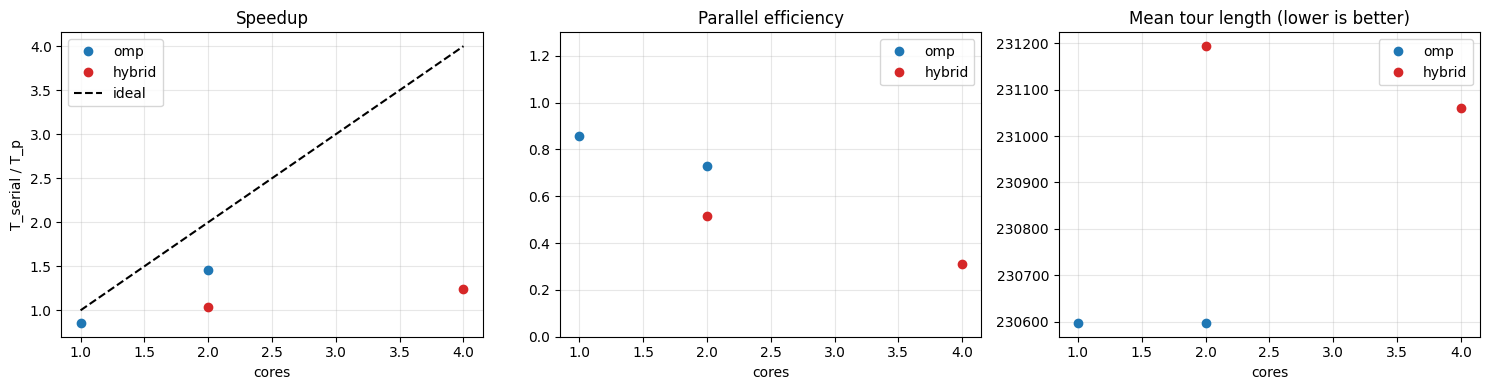

In [ ]:
REPS = 3
configs = [("serial", "./tsp_serial", 1, None)]
configs += [(f"omp x{t}", "./tsp_omp", t, None) for t in range(1, CORES + 1)]
configs += [(f"hybrid {r}x{t}", "./tsp_hybrid", t, r) for r in (2, 4) for t in range(1, max(1, CORES // r) + 1)]

rows = []
for label, exe, t, r in configs:
    for s in range(REPS):
        L, T, gap = run(exe, INSTANCE, pop=64, gens=100, threads=t, ranks=r, seed=100 + s)
        rows.append(dict(config=label, cores=t * (r or 1), ranks=r or 1, threads=t, time=T, length=L))
df = pd.DataFrame(rows)
g = df.groupby(["config", "cores"]).agg(time=("time", "mean"), length=("length", "mean")).reset_index()
t_serial = g.loc[g.config == "serial", "time"].iloc[0]
g["speedup"] = t_serial / g.time
g["efficiency"] = g.speedup / g.cores
g = g.sort_values(["cores", "config"])
display(g.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for kind, c in (("omp", "tab:blue"), ("hybrid", "tab:red")):
    s = g[g.config.str.startswith(kind)]
    ax[0].plot(s.cores, s.speedup, "o", c=c, label=kind)
    ax[1].plot(s.cores, s.efficiency, "o", c=c, label=kind)
    ax[2].plot(s.cores, s.length, "o", c=c, label=kind)
mx = g.cores.max()
ax[0].plot([1, mx], [1, mx], "k--", label="ideal")
ax[0].set(title="Speedup", xlabel="cores", ylabel="T_serial / T_p")
ax[1].set(title="Parallel efficiency", xlabel="cores", ylim=(0, 1.3))
ax[2].set(title="Mean tour length (lower is better)", xlabel="cores")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Experiment B: migration frequency and size
Island model with 4 ranks. `mig_int = 0` means isolated islands (no communication). All runs use the same total work,
so differences come from how often (and how many) good tours are exchanged.

mig_count,1,2,4
mig_int,,,
0,NaN,231861.3,NaN
2,231014.3,231312.3,231399.7
5,231383.3,231012.3,231032.3
10,231624.0,231079.0,231275.7
25,231658.3,231628.7,231703.0


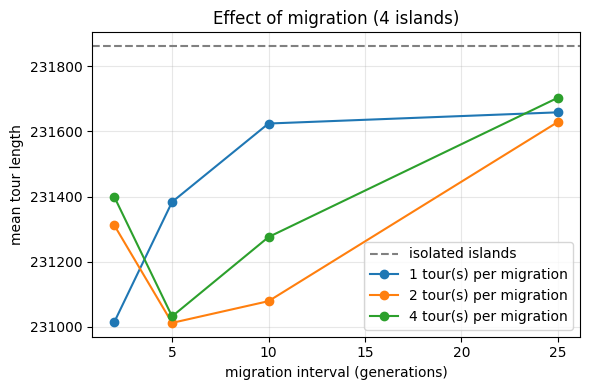

In [ ]:
RANKS = 4
rows = []
for mi in (0, 2, 5, 10, 25):
    for mc in ((2,) if mi == 0 else (1, 2, 4)):
        for s in range(3):
            L, T, gap = run("./tsp_hybrid", INSTANCE, pop=64, gens=100, threads=1, ranks=RANKS, seed=200 + s,
                            extra=["--mig-int", str(mi), "--mig-count", str(mc)])
            rows.append(dict(mig_int=mi, mig_count=mc, length=L, time=T))
m = pd.DataFrame(rows)
tab = m.groupby(["mig_int", "mig_count"]).length.mean().unstack()
display(tab.round(1))

fig, ax = plt.subplots(figsize=(6, 4))
iso = tab.loc[0].dropna().iloc[0]
ax.axhline(iso, color="gray", ls="--", label="isolated islands")
for mc in tab.columns:
    s = tab[mc].drop(index=0).dropna()
    ax.plot(s.index, s.values, "o-", label=f"{mc} tour(s) per migration")
ax.set(xlabel="migration interval (generations)", ylabel="mean tour length", title=f"Effect of migration ({RANKS} islands)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 8. Experiment C: plain GA vs memetic GA vs parallel memetic islands
`--ls 0` disables local search and gives the textbook GA from the proposal. Gap is measured against the best known TSPLIB value.

In [ ]:
names = ["eil51", "kroA100", "ch150", "a280", "pcb442"]
rows = []
for nm in names:
    inst = get_instance(nm)
    for s in range(3):
        _, _, g1 = run("./tsp_serial", inst, pop=64, gens=100, seed=s, extra=["--ls", "0"])
        _, _, g2 = run("./tsp_serial", inst, pop=64, gens=100, seed=s)
        _, _, g3 = run("./tsp_hybrid", inst, pop=64, gens=100, seed=s, ranks=4, threads=1)
        for v, gg in (("plain GA (serial)", g1), ("memetic (serial)", g2), ("memetic islands x4", g3)):
            rows.append(dict(instance=nm, variant=v, gap=gg))
q = pd.DataFrame(rows)
if q.gap.notna().any():
    qt = q.groupby(["instance", "variant"]).gap.mean().unstack()
    display(qt.round(2))
    qt.plot.bar(figsize=(9, 4)); plt.ylabel("gap to optimum (%)"); plt.yscale("log"); plt.title("Solution quality"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else:
    print("TSPLIB download unavailable (no gap computed). Check internet access in the runtime.")

[download of eil51 failed (<urlopen error timed out>); using a random instance with n=51]
[download of kroA100 failed (<urlopen error timed out>); using a random instance with n=100]
[download of ch150 failed (<urlopen error timed out>); using a random instance with n=150]
[download of a280 failed (<urlopen error timed out>); using a random instance with n=280]
[download of pcb442 failed (<urlopen error timed out>); using a random instance with n=442]
TSPLIB download unavailable (no gap computed). Check internet access in the runtime.


## 9. Visualise the best tour

[download of pcb442 failed (<urlopen error timed out>); using a random instance with n=442]


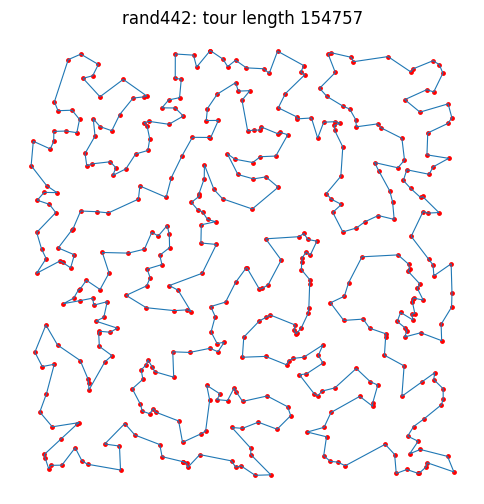

In [ ]:
def read_coords(path):
    pts, on = [], False
    for line in open(path):
        if "NODE_COORD_SECTION" in line: on = True; continue
        if "EOF" in line: break
        if on:
            p = line.split()
            if len(p) >= 3: pts.append((float(p[1]), float(p[2])))
    return pts

def read_tour(path):
    t, on = [], False
    for line in open(path):
        if "TOUR_SECTION" in line: on = True; continue
        if on:
            v = int(line.split()[0])
            if v == -1: break
            t.append(v - 1)
    return t

inst = get_instance("pcb442")
nm = os.path.basename(inst).replace(".tsp", "")
L, T, gap = run("./tsp_hybrid", inst, pop=64, gens=150, ranks=2, threads=max(1, CORES // 2), extra=["--out", "best.tour"])
pts, tour = read_coords(inst), read_tour("best.tour")
xs = [pts[c][0] for c in tour + tour[:1]]; ys = [pts[c][1] for c in tour + tour[:1]]
plt.figure(figsize=(6, 6)); plt.plot(xs, ys, "-", lw=0.8); plt.scatter(xs, ys, s=6, c="red")
plt.title(f"{nm}: tour length {L}" + (f" (gap {gap:.2f}%)" if gap is not None else "")); plt.axis("equal"); plt.axis("off"); plt.show()

## 10. Your own experiments
Try different settings by calling `run(...)`:
```python
run("./tsp_hybrid", INSTANCE, pop=128, gens=200, ranks=4, threads=1, extra=["--mig-int", "5", "--mig-count", "2"])
```
Useful options: `--ls 0` (plain GA), `--stag S` (stagnation kicks), `--pm x` (mutation probability), `--strong`/no `--strong`
(strong vs weak scaling; pass `strong=False` to `run`). Run `!./tsp_serial --help` for everything.

**Reading the results:** on 2 cores the maximum speedup is about 2. With `--strong`, splitting the population across many islands makes each island small,
so tour quality can drop slightly; this is the speedup-versus-quality trade-off discussed in the report.